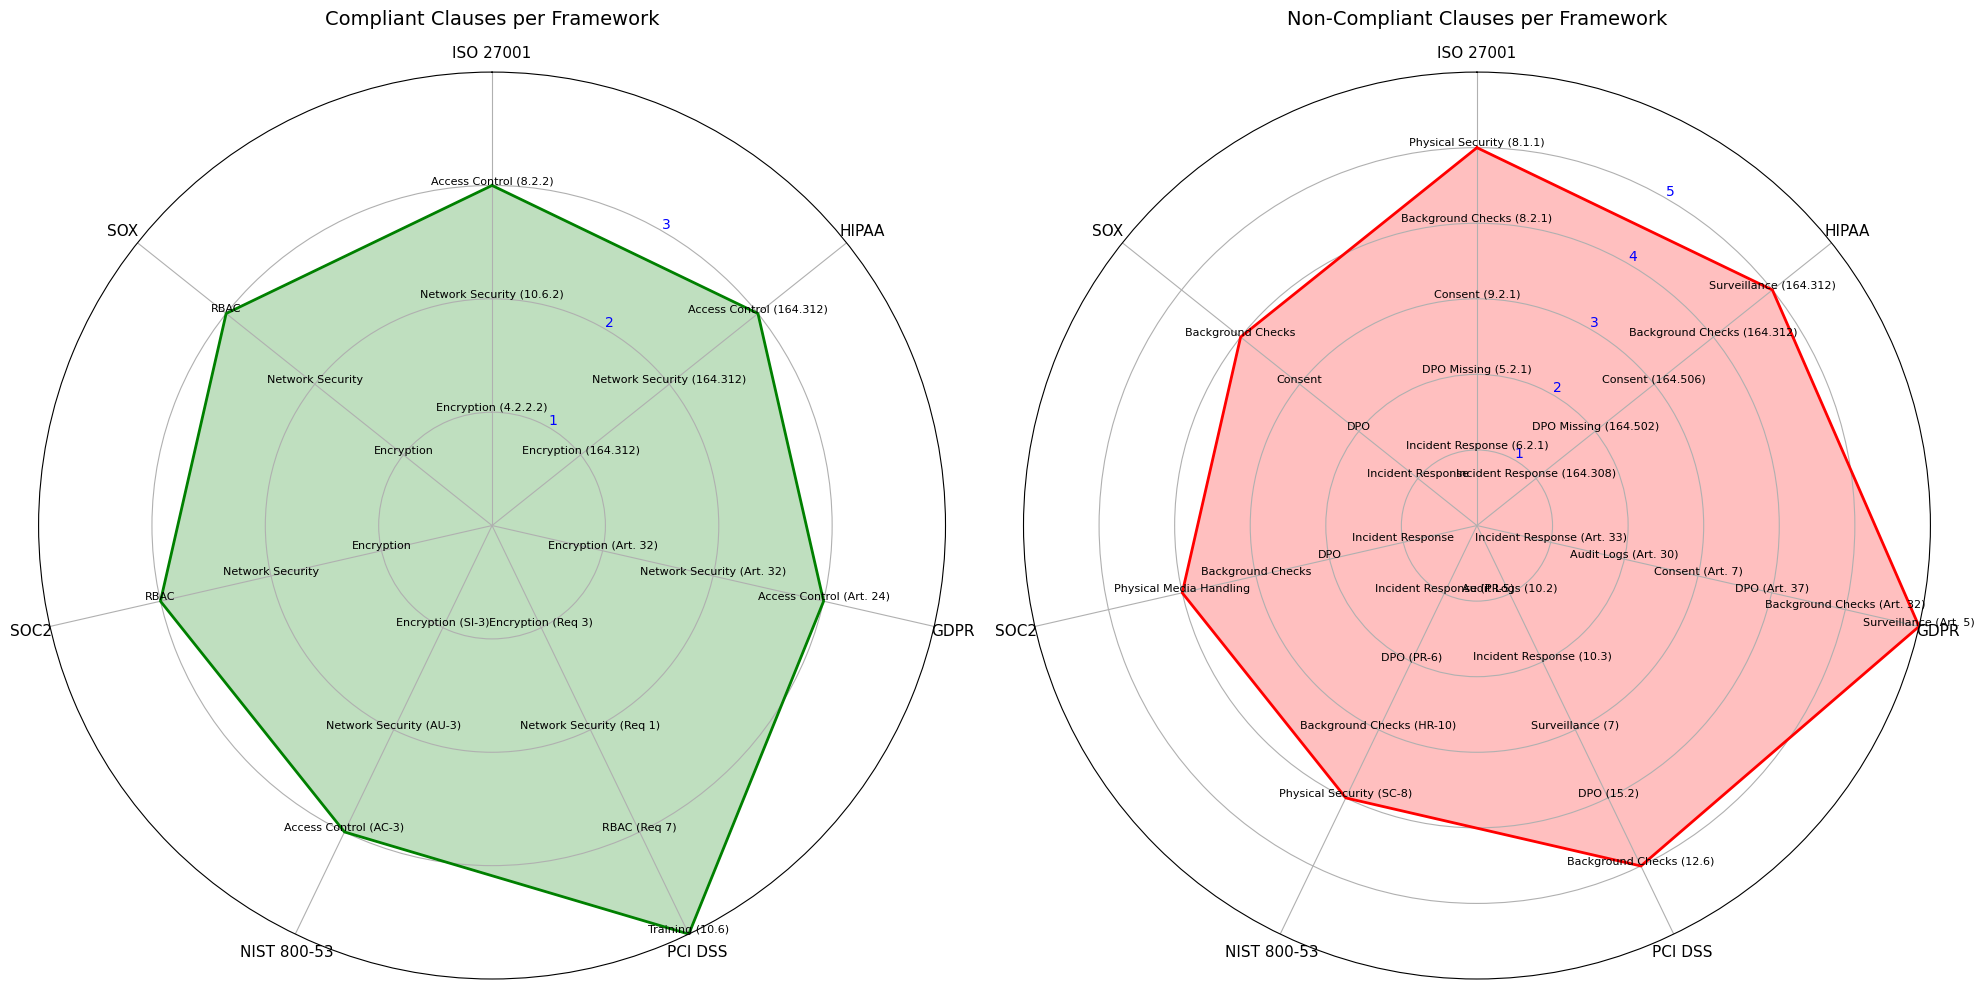

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Clause-wise data for each framework
compliant_clauses = {
    "ISO 27001": ["Encryption (4.2.2.2)", "Network Security (10.6.2)", "Access Control (8.2.2)"],
    "HIPAA": ["Encryption (164.312)", "Network Security (164.312)", "Access Control (164.312)"],
    "GDPR": ["Encryption (Art. 32)", "Network Security (Art. 32)", "Access Control (Art. 24)"],
    "PCI DSS": ["Encryption (Req 3)", "Network Security (Req 1)", "RBAC (Req 7)", "Training (10.6)"],
    "NIST 800-53": ["Encryption (SI-3)", "Network Security (AU-3)", "Access Control (AC-3)"],
    "SOC2": ["Encryption", "Network Security", "RBAC"],
    "SOX": ["Encryption", "Network Security", "RBAC"]
}

non_compliant_clauses = {
    "ISO 27001": ["Incident Response (6.2.1)", "DPO Missing (5.2.1)", "Consent (9.2.1)", "Background Checks (8.2.1)", "Physical Security (8.1.1)"],
    "HIPAA": ["Incident Response (164.308)", "DPO Missing (164.502)", "Consent (164.506)", "Background Checks (164.312)", "Surveillance (164.312)"],
    "GDPR": ["Incident Response (Art. 33)", "Audit Logs (Art. 30)", "Consent (Art. 7)", "DPO (Art. 37)", "Background Checks (Art. 32)", "Surveillance (Art. 5)"],
    "PCI DSS": ["Audit Logs (10.2)", "Incident Response (10.3)", "Surveillance (7)", "DPO (15.2)", "Background Checks (12.6)"],
    "NIST 800-53": ["Incident Response (PR-5)", "DPO (PR-6)", "Background Checks (HR-10)", "Physical Security (SC-8)"],
    "SOC2": ["Incident Response", "DPO", "Background Checks", "Physical Media Handling"],
    "SOX": ["Incident Response", "DPO", "Consent", "Background Checks"]
}

frameworks = list(compliant_clauses.keys())
num_vars = len(frameworks)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # to close the loop

def plot_radar(ax, data, title, color):
    labels = list(data.keys())
    values = [len(clauses) for clauses in data.values()]
    values += values[:1]

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=11)
    ax.plot(angles, values, color=color, linewidth=2)
    ax.fill(angles, values, color=color, alpha=0.25)

    # Add upright clause names
    for i, (framework, clauses) in enumerate(data.items()):
        angle = angles[i]
        for j, clause in enumerate(clauses):
            radius = j + 1
            ax.text(angle, radius, clause, ha='center', va='bottom', fontsize=8, rotation=0)

    ax.set_title(title, size=14, pad=15)
    ax.set_rlabel_position(30)
    ax.set_rticks(range(1, max(values)))
    ax.set_ylim(0, max(values))

    # Force render to access tick labels
    plt.draw()

    # Rotate and recolor radial (y-axis) tick labels
    tick_labels = ax.get_yticklabels()
    for label in tick_labels:
        label.set_rotation(30)
        label.set_color('blue')
        label.set_fontsize(10)
        label.set_verticalalignment('bottom')
        label.set_horizontalalignment('left')  


# === PLOT BOTH CHARTS ===
fig, axs = plt.subplots(1, 2, figsize=(20, 10), subplot_kw=dict(polar=True))

plot_radar(axs[0], compliant_clauses, "Compliant Clauses per Framework", "green")
plot_radar(axs[1], non_compliant_clauses, "Non-Compliant Clauses per Framework", "red")

plt.tight_layout()

# ✅ Save to PNG before showing
# plt.savefig("compliance_radar_charts.png", dpi=300)

plt.show()


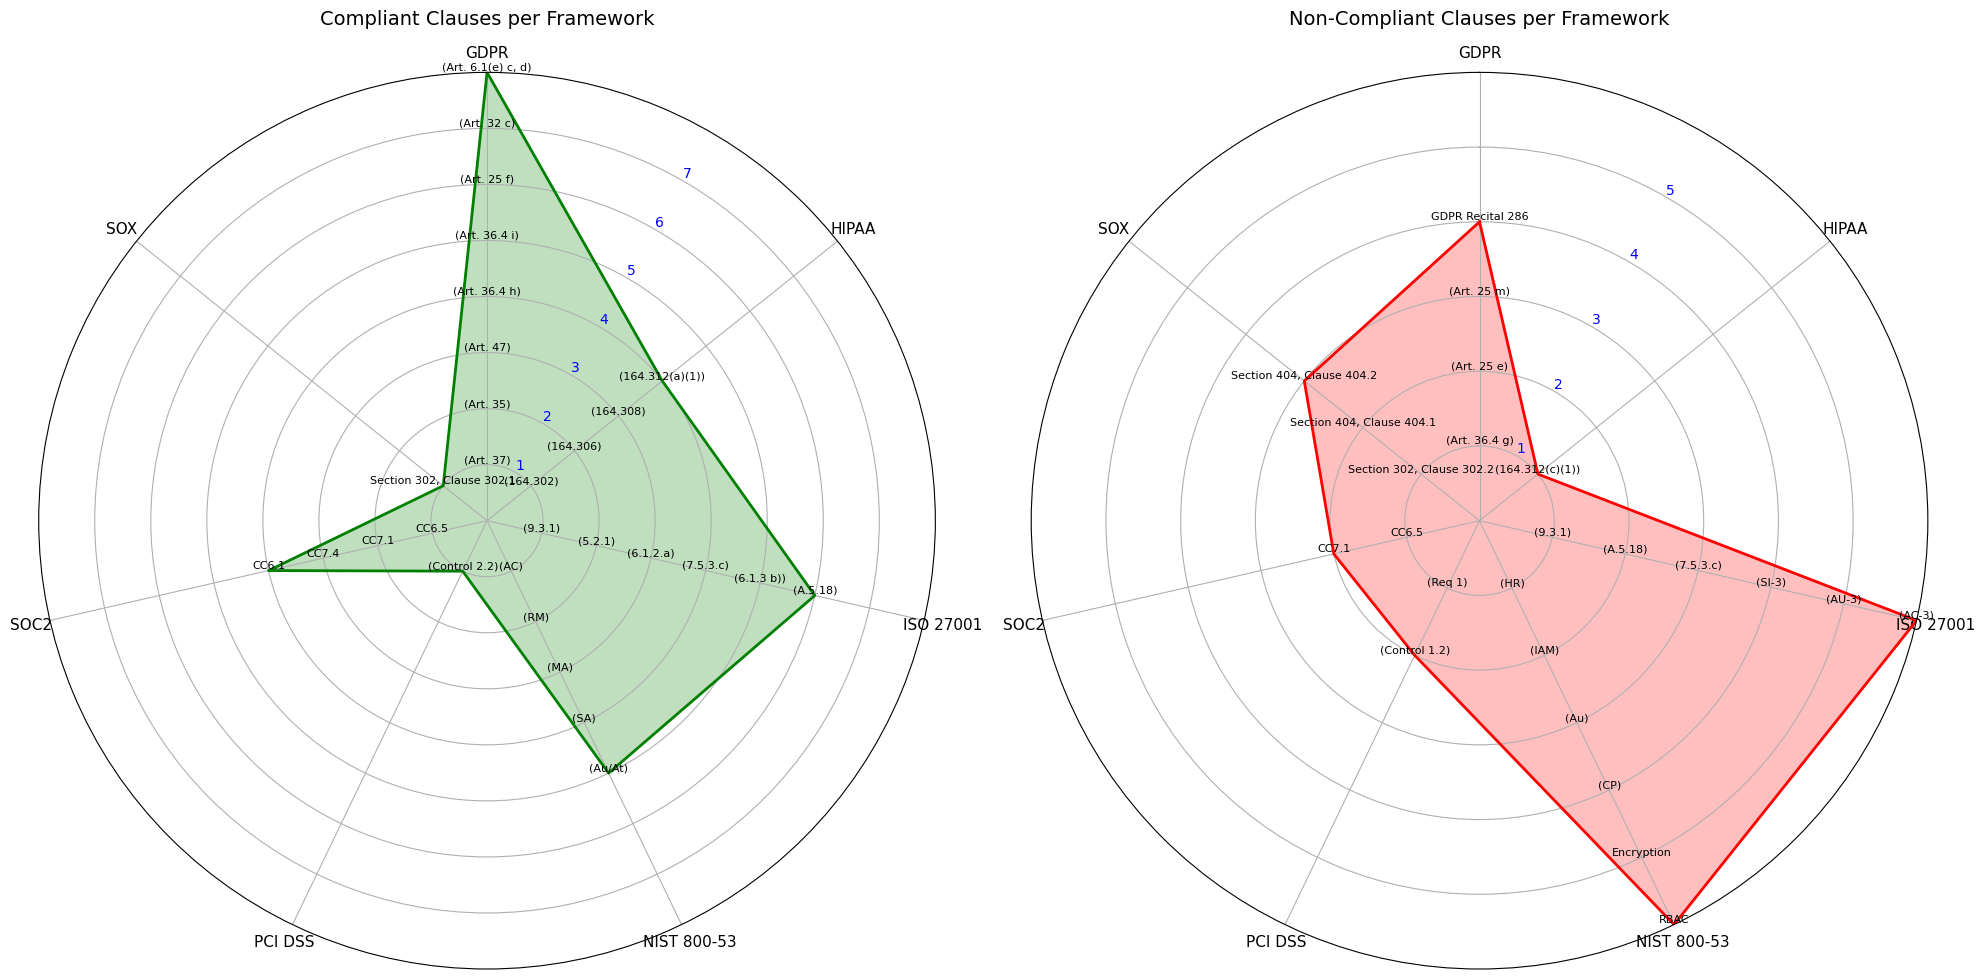

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# ✅ Strict Replacement: Import cleaned clause data
from Clauses_Clean import compliant_clauses, non_compliant_clauses

#print(compliant_clauses, non_compliant_clauses)

frameworks = list(compliant_clauses.keys())
num_vars = len(frameworks)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # to close the loop

def plot_radar(ax, data, title, color):
    labels = list(data.keys())
    values = [len(clauses) for clauses in data.values()]
    values += values[:1]

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=11)
    ax.plot(angles, values, color=color, linewidth=2)
    ax.fill(angles, values, color=color, alpha=0.25)

    # Add upright clause names
    for i, (framework, clauses) in enumerate(data.items()):
        angle = angles[i]
        for j, clause in enumerate(clauses):
            radius = j + 1
            ax.text(angle, radius, clause, ha='center', va='bottom', fontsize=8, rotation=0)

    ax.set_title(title, size=14, pad=15)
    ax.set_rlabel_position(30)
    ax.set_rticks(range(1, max(values)))
    ax.set_ylim(0, max(values))

    # Force render to access tick labels
    plt.draw()

    # Rotate and recolor radial (y-axis) tick labels
    tick_labels = ax.get_yticklabels()
    for label in tick_labels:
        label.set_rotation(30)
        label.set_color('blue')
        label.set_fontsize(10)
        label.set_verticalalignment('bottom')
        label.set_horizontalalignment('left')  


# === PLOT BOTH CHARTS ===
fig, axs = plt.subplots(1, 2, figsize=(20, 10), subplot_kw=dict(polar=True))

plot_radar(axs[0], compliant_clauses, "Compliant Clauses per Framework", "green")
plot_radar(axs[1], non_compliant_clauses, "Non-Compliant Clauses per Framework", "red")

plt.tight_layout()

# ✅ Save to PNG before showing
plt.savefig("Compliance_Radar_Charts.png", dpi=300)

plt.show()